# Real-pool pose model: YOLO11s-pose distilled from ViTPose-L SwimXYZ (experimental)

**What this is.** ViTPose-L SwimXYZ (teacher, ~34 ms/frame on T4) labels our 362 real pool frames. YOLO11s-pose
(student, ~12 ms/frame, COCO-pose pretrained) is fine-tuned on those labels. This is **knowledge distillation with
pseudo-labels**.

**Labels are `ai_reference_unverified`.** They are ViTPose predictions, not human ground truth.
- The student can at best copy the teacher, including its mistakes.
- Every metric here is **agreement with ViTPose**, not accuracy. ViTPose itself is not evaluated (it would score itself).
- Splits: train = 300 `real_train` frames, val = 35 other `real_val` frames (model selection), test = the 27 selected
  `real_val` frames (never trained on). Train and val/test are separate frame-index blocks of the same footage.

Not connected to the Lifeguard system. Run the cells in order; each cell prints what to check.


## 0. Drive and inputs

In [77]:
# 0. Mount Drive, paths, check inputs
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
OUTD = Path('/content/drive/MyDrive/pose_baseline')
MODELS = OUTD / 'models'
ONNX = MODELS / 'vitpose-l-swimxyz-mv.onnx'
YOLO_PT = MODELS / 'yolo11s-pose.pt'
SET_ZIP = OUTD / 'pose_annotation_set_v2.zip'
REF_DIR = OUTD / 'ai_reference'
RUNS = OUTD / 'runs_pose'
for f in (ONNX, YOLO_PT, SET_ZIP):
    assert f.is_file(), f'missing: {f}'
    print('OK', f.name, round(f.stat().st_size / 1e6, 1), 'MB')
REF_DIR.mkdir(exist_ok=True)
RUNS.mkdir(exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK vitpose-l-swimxyz-mv.onnx 1234.4 MB
OK yolo11s-pose.pt 20.4 MB
OK pose_annotation_set_v2.zip 102.9 MB
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Install

In [78]:
# 1. Install
!pip -q install onnxruntime-gpu ultralytics
import ultralytics, onnxruntime, sys
print('python', sys.version.split()[0], '| ultralytics', ultralytics.__version__, '| onnxruntime', onnxruntime.__version__)
!mkdir -p /content/pose_tools


python 3.13.16 | ultralytics 8.4.220 | onnxruntime 1.32.0


## 2. Tools (generated from `python_scripts/pose/`)

In [79]:
%%writefile /content/pose_tools/pose_common.py
"""Shared helpers for the pose proposal / zero-shot tools (no project imports).

Top-down model contract (from the ViTPose-L SwimXYZ model card): input (N, 3, 256, 192) float32,
ImageNet-normalised RGB crop; output (N, 17, 64, 48) heatmaps in COCO-17 order.
Pure-numpy parts (box->crop parameters, heatmap decoding, PCK) are testable without weights.
"""
from __future__ import annotations

import math
from typing import Any

import numpy as np

COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder",
          "left_elbow", "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip",
          "left_knee", "right_knee", "left_ankle", "right_ankle"]
UPPER_BODY = [0, 5, 6, 7, 8, 9, 10]  # nose, shoulders, elbows, wrists
COCO_SKELETON = [[16, 14], [14, 12], [17, 15], [15, 13], [12, 13], [6, 12], [7, 13], [6, 7], [6, 8],
                 [7, 9], [8, 10], [9, 11], [2, 3], [1, 2], [1, 3], [2, 4], [3, 5], [4, 6], [5, 7]]
IN_W, IN_H = 192, 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def crop_params(box_xyxy: tuple[float, float, float, float], scale: float = 1.25) -> tuple[float, float, float]:
    """Return (x0, y0, s) of the crop window: window covers IN_W/s x IN_H/s pixels, box centred, padded."""
    x1, y1, x2, y2 = box_xyxy
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = max(x2 - x1, 1.0) * scale, max(y2 - y1, 1.0) * scale
    if bw / bh > IN_W / IN_H:
        bh = bw * IN_H / IN_W
    else:
        bw = bh * IN_W / IN_H
    s = IN_W / bw
    return cx - bw / 2, cy - bh / 2, s


def preprocess(frame_bgr: np.ndarray, box_xyxy: tuple[float, float, float, float]
               ) -> tuple[np.ndarray, tuple[float, float, float]]:
    import cv2  # lazy: Colab has it

    x0, y0, s = crop_params(box_xyxy)
    m = np.array([[s, 0, -x0 * s], [0, s, -y0 * s]], dtype=np.float32)
    crop = cv2.warpAffine(frame_bgr, m, (IN_W, IN_H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rgb = crop[:, :, ::-1].astype(np.float32) / 255.0
    rgb = (rgb - MEAN) / STD
    return rgb.transpose(2, 0, 1)[None], (x0, y0, s)


def decode_heatmaps(hm: np.ndarray, params: tuple[float, float, float]) -> np.ndarray:
    """hm: (17, H, W) -> (17, 3) [x, y, score] in image pixels (argmax, +quarter-pixel shift)."""
    k, h, w = hm.shape
    x0, y0, s = params
    out = np.zeros((k, 3), dtype=np.float32)
    for i in range(k):
        flat = int(np.argmax(hm[i]))
        iy, ix = divmod(flat, w)
        score = float(hm[i, iy, ix])
        fx, fy = float(ix), float(iy)
        if 0 < ix < w - 1:
            fx += 0.25 * np.sign(hm[i, iy, ix + 1] - hm[i, iy, ix - 1])
        if 0 < iy < h - 1:
            fy += 0.25 * np.sign(hm[i, iy + 1, ix] - hm[i, iy - 1, ix])
        cx, cy = (fx + 0.5) * IN_W / w, (fy + 0.5) * IN_H / h  # crop pixels
        out[i] = (cx / s + x0, cy / s + y0, score)
    return out


class OnnxVitPose:
    """Top-down ONNX pose model (ViTPose-L SwimXYZ export). Input name is read from the graph."""

    def __init__(self, path: str, providers: list[str] | None = None) -> None:
        import onnxruntime as ort

        self.sess = ort.InferenceSession(path, providers=providers or ["CUDAExecutionProvider",
                                                                         "CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name

    def predict(self, frame_bgr: np.ndarray, boxes: list[tuple[float, float, float, float]]) -> list[np.ndarray]:
        res = []
        for b in boxes:
            x, params = preprocess(frame_bgr, b)
            hm = self.sess.run(None, {self.input_name: x})[0][0]
            res.append(decode_heatmaps(hm, params))
        return res


def iou(a: tuple[float, ...], b: tuple[float, ...]) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pck(pred: np.ndarray, gt: np.ndarray, box_xyxy: tuple[float, ...], thr: float,
        idx: list[int] | None = None) -> tuple[int, int]:
    """(correct, total) over GT keypoints with visibility > 0. Normaliser: longer side of the GT box."""
    norm = max(box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], 1.0)
    ok = tot = 0
    for i in idx if idx is not None else range(len(gt)):
        if gt[i][2] <= 0:
            continue
        tot += 1
        if math.hypot(pred[i][0] - gt[i][0], pred[i][1] - gt[i][1]) <= thr * norm:
            ok += 1
    return ok, tot


def confident_upper(pred: np.ndarray, min_conf: float = 0.5) -> int:
    return int(sum(1 for i in UPPER_BODY if pred[i][2] >= min_conf))


def as_info(**kw: Any) -> dict[str, Any]:
    return kw


Overwriting /content/pose_tools/pose_common.py


In [80]:
%%writefile /content/pose_tools/zero_shot_eval.py
"""Zero-shot comparison of pose models on HAND-CORRECTED frames (CVAT export, COCO keypoints 1.0).

Metrics (all on GT keypoints with visibility > 0; normaliser = longer side of the GT box):
  PCK@0.05 / 0.1 / 0.2 on upper body (nose, shoulders, elbows, wrists) and on all 17,
  share of frames with >= 3 confident (>=0.5) upper-body keypoints, latency per person.
Models (any subset):
  --vitpose-onnx   ViTPose-L SwimXYZ ONNX, top-down on the GT box
  --yolo-pose      Ultralytics pose weights, full frame; the prediction with best IoU to the GT box is used
Only run on the `real_val` frames; select with --split-manifest + --split real_val. Report per camera type via --group.
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np

from pose_common import UPPER_BODY, OnnxVitPose, confident_upper, iou, pck

THRS = (0.05, 0.1, 0.2)


def load_gt(coco_path: Path) -> dict[str, tuple[np.ndarray, tuple[float, float, float, float]]]:
    d = json.loads(coco_path.read_text(encoding="utf-8"))
    names = {i["id"]: i["file_name"] for i in d["images"]}
    out = {}
    for a in d["annotations"]:
        k = np.array(a["keypoints"], dtype=np.float32).reshape(-1, 3)
        if k.shape[0] != 17:
            raise SystemExit(f"annotation {a['id']} has {k.shape[0]} keypoints, expected 17 (COCO order)")
        x, y, w, h = a["bbox"]
        out[Path(names[a["image_id"]]).name] = (k, (x, y, x + w, y + h))
    return out


def run_vitpose(model: OnnxVitPose, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray:
    return model.predict(img, [box])[0]


def run_yolo(model, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray | None:  # noqa: ANN001
    res = model.predict(img, verbose=False)[0]
    if res.keypoints is None or len(res.boxes) == 0:
        return None
    best, best_iou = None, 0.0
    for i, b in enumerate(res.boxes.xyxy.cpu().numpy()):
        v = iou(tuple(b), box)
        if v > best_iou:
            best, best_iou = i, v
    if best is None or best_iou < 0.3:
        return None
    xy = res.keypoints.xy[best].cpu().numpy()
    cf = res.keypoints.conf[best].cpu().numpy() if res.keypoints.conf is not None else np.ones(17)
    return np.concatenate([xy, cf[:, None]], axis=1)


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--gt", type=Path, required=True, help="CVAT export (COCO keypoints 1.0) json")
    ap.add_argument("--images", type=Path, required=True, help="folder with the images of the set")
    ap.add_argument("--manifest", type=Path, help="manifest.csv, to restrict to --split")
    ap.add_argument("--split", default="real_val")
    ap.add_argument("--group", default="", help="substring of image name defining a camera group, e.g. 'ddt'")
    ap.add_argument("--vitpose-onnx", type=str)
    ap.add_argument("--yolo-pose", type=str)
    ap.add_argument("--out", type=Path, default=Path("zero_shot_results.csv"))
    a = ap.parse_args()

    if not a.gt.is_file():
        raise SystemExit(f"GT file not found: {a.gt}. Export the corrected real_val frames from CVAT first "
                         "(see docs/POSE_ANNOTATION_GUIDE.md); this step cannot run before that.")
    gt = load_gt(a.gt)
    names = set(gt)
    if a.manifest:
        names &= {Path(r["image"]).name for r in csv.DictReader(open(a.manifest, encoding="utf-8"))
                  if r["split"] == a.split}
    if a.group:
        names = {n for n in names if a.group in n}
    names = sorted(names)
    if not names:
        raise SystemExit("no frames selected: check --split / --group / file names")
    print(f"{len(names)} frames, split={a.split}, group={a.group or 'all'}")

    runners = {}
    if a.vitpose_onnx:
        m = OnnxVitPose(a.vitpose_onnx)
        runners["vitpose_swimxyz"] = lambda im, b: run_vitpose(m, im, b)
    if a.yolo_pose:
        from ultralytics import YOLO

        y = YOLO(a.yolo_pose)
        runners[Path(a.yolo_pose).stem] = lambda im, b: run_yolo(y, im, b)
    if not runners:
        raise SystemExit("give --vitpose-onnx and/or --yolo-pose")

    rows = []
    for mname, fn in runners.items():
        acc = {(s, t): [0, 0] for s in ("upper", "all") for t in THRS}
        n_conf3 = n_missing = 0
        times = []
        for n in names:
            img = cv2.imread(str(a.images / n))
            k, box = gt[n]
            t0 = time.perf_counter()
            pred = fn(img, box)
            times.append((time.perf_counter() - t0) * 1000)
            if pred is None:
                n_missing += 1
                pred = np.zeros((17, 3), dtype=np.float32)
                pred[:, :2] = -1e6
            n_conf3 += confident_upper(pred) >= 3
            for t in THRS:
                for s, idx in (("upper", UPPER_BODY), ("all", None)):
                    ok, tot = pck(pred, k, box, t, idx)
                    acc[(s, t)][0] += ok
                    acc[(s, t)][1] += tot
        row = {"model": mname, "frames": len(names), "no_prediction": n_missing,
               "frames_ge3_confident_upper": round(n_conf3 / len(names), 3),
               "latency_ms_median_per_person": round(float(np.median(times)), 1)}
        for (s, t), (ok, tot) in acc.items():
            row[f"PCK@{t}_{s}"] = round(ok / tot, 3) if tot else None
        rows.append(row)
        print(row)
    with open(a.out, "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows[0]))
        wr.writeheader()
        wr.writerows(rows)
    print("wrote", a.out)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting /content/pose_tools/zero_shot_eval.py


In [81]:
%%writefile /content/pose_tools/make_ai_reference.py
"""ViTPose-L SwimXYZ keypoints (with per-keypoint scores) for chosen frames, saved as COCO keypoints.

Every annotation is marked provenance = "ai_reference_unverified". These are MODEL OUTPUTS, not human ground truth:
  - as training labels they are pseudo-labels (teacher -> student distillation);
  - as evaluation targets they measure agreement with ViTPose, not accuracy.
Keypoints with score < --min-score are written unlabelled (0, 0, 0); the raw scores are kept in "scores".
Inputs are only read: images, manifest.csv and existing JSON files are never modified.
"""
from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path

import cv2
import numpy as np

from pose_common import COCO17, COCO_SKELETON, UPPER_BODY, OnnxVitPose

PROVENANCE = "ai_reference_unverified"


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--set", type=Path, required=True, help="folder with manifest.csv and images/")
    ap.add_argument("--onnx", required=True)
    ap.add_argument("--out", type=Path, required=True, help="output JSON path")
    ap.add_argument("--frames", type=Path, help="optional text file, one image file name per line")
    ap.add_argument("--min-score", type=float, default=0.5)
    a = ap.parse_args()

    rows = list(csv.DictReader(open(a.set / "manifest.csv", encoding="utf-8")))
    if a.frames:
        want = {ln.strip() for ln in a.frames.read_text().splitlines() if ln.strip()}
        rows = [r for r in rows if Path(r["image"]).name in want]
        missing = want - {Path(r["image"]).name for r in rows}
        if missing:
            raise SystemExit(f"frames not in manifest: {sorted(missing)}")
    model = OnnxVitPose(a.onnx)
    images, anns, all_scores = [], [], []
    for i, r in enumerate(sorted(rows, key=lambda r: r["image"]), start=1):
        img = cv2.imread(str(a.set / r["image"]))
        if img is None:
            raise SystemExit(f"cannot read {r['image']}")
        h, w = img.shape[:2]
        box = tuple(float(r[k]) for k in ("x1", "y1", "x2", "y2"))
        kp = model.predict(img, [box])[0]
        flat, n_lab = [], 0
        for x, y, s in kp:
            if s >= a.min_score and 0 <= x <= w and 0 <= y <= h:
                flat += [round(float(x), 1), round(float(y), 1), 2]
                n_lab += 1
            else:
                flat += [0, 0, 0]
        all_scores.append(kp[:, 2])
        images.append({"id": i, "file_name": Path(r["image"]).name, "width": w, "height": h})
        anns.append({"id": i, "image_id": i, "category_id": 1, "iscrowd": 0, "num_keypoints": n_lab,
                     "keypoints": flat, "scores": [round(float(s), 4) for s in kp[:, 2]],
                     "bbox": [box[0], box[1], box[2] - box[0], box[3] - box[1]],
                     "area": (box[2] - box[0]) * (box[3] - box[1]),
                     "split": r["split"], "provenance": PROVENANCE})
    coco = {"images": images, "annotations": anns,
            "categories": [{"id": 1, "name": "person", "supercategory": "person",
                            "keypoints": COCO17, "skeleton": COCO_SKELETON}],
            "info": {"provenance": PROVENANCE, "model": Path(a.onnx).name, "min_score": a.min_score,
                     "note": "Model predictions. NOT human ground truth."}}
    a.out.parent.mkdir(parents=True, exist_ok=True)
    a.out.write_text(json.dumps(coco), encoding="utf-8")

    sc = np.array(all_scores)
    print(f"wrote {a.out}: {len(images)} frames, provenance={PROVENANCE}, min_score={a.min_score}")
    print(f"labelled keypoints per frame: mean {np.mean([x['num_keypoints'] for x in anns]):.1f} of 17")
    print(f"frames with < 3 upper-body keypoints labelled: "
          f"{int(sum((s[UPPER_BODY] >= a.min_score).sum() < 3 for s in sc))}")
    print("keypoint            mean score   missing (< min_score)")
    for k, name in enumerate(COCO17):
        print(f"  {name:16s}  {sc[:, k].mean():.2f}        {int((sc[:, k] < a.min_score).sum())}/{len(sc)}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/pose_tools/make_ai_reference.py


In [82]:
%%writefile /content/pose_tools/build_yolo_pose_dataset.py
"""Build an Ultralytics YOLO-pose dataset from AI reference labels (pseudo-labels, provenance ai_reference_unverified).

Splits (no frame in two splits):
  train = manifest real_train (300)          -> pseudo-labels to learn from
  val   = manifest real_val NOT in test list  -> model selection / early stopping
  test  = the frames in --test-list (27)      -> exploratory evaluation only, never trained on
Boxes come from the manifest (the source dataset's own person boxes). Keypoints come from --refs; a keypoint is
labelled (v=2) only if its ViTPose score >= --min-score, else (0, 0, 0) so the loss ignores it.
Images are copied; nothing in --set is modified.
"""
from __future__ import annotations

import argparse
import csv
import json
import shutil
from collections import Counter
from pathlib import Path

FLIP_IDX = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]  # COCO-17 left/right swap


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--set", type=Path, required=True, help="folder with manifest.csv and images/")
    ap.add_argument("--refs", type=Path, required=True, help="AI reference JSON for all frames (make_ai_reference.py)")
    ap.add_argument("--test-list", type=Path, required=True, help="text file: test frame names, one per line")
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--min-score", type=float, default=0.5)
    a = ap.parse_args()

    rows = {Path(r["image"]).name: r for r in csv.DictReader(open(a.set / "manifest.csv", encoding="utf-8"))}
    test = {ln.strip() for ln in a.test_list.read_text().splitlines() if ln.strip()}
    bad = [n for n in test if n not in rows or rows[n]["split"] != "real_val"]
    if bad:
        raise SystemExit(f"test frames must be real_val frames in the manifest: {bad}")
    refs = json.loads(a.refs.read_text(encoding="utf-8"))
    img_by_id = {i["id"]: i for i in refs["images"]}
    ann_by_name = {img_by_id[x["image_id"]]["file_name"]: x for x in refs["annotations"]}
    missing = sorted(set(rows) - set(ann_by_name))
    if missing:
        raise SystemExit(f"{len(missing)} manifest frames have no reference annotation, e.g. {missing[:3]}")

    def split_of(n: str) -> str:
        if n in test:
            return "test"
        return "train" if rows[n]["split"] == "real_train" else "val"

    for sp in ("train", "val", "test"):
        (a.out / "images" / sp).mkdir(parents=True, exist_ok=True)
        (a.out / "labels" / sp).mkdir(parents=True, exist_ok=True)
    counts, vis = Counter(), Counter()
    with open(a.out / "split_manifest.csv", "w", newline="", encoding="utf-8") as f:
        wr = csv.writer(f)
        wr.writerow(["image", "split", "label_provenance"])
        for n, r in sorted(rows.items()):
            sp = split_of(n)
            ann = ann_by_name[n]
            im = img_by_id[ann["image_id"]]
            w, h = im["width"], im["height"]
            x1, y1, x2, y2 = (float(r[k]) for k in ("x1", "y1", "x2", "y2"))
            x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
            vals = [0, (x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h]
            kp = ann["keypoints"]
            scores = ann.get("scores") or [1.0 if kp[3 * k + 2] > 0 else 0.0 for k in range(17)]
            for k in range(17):
                x, y, v = kp[3 * k: 3 * k + 3]
                if v > 0 and scores[k] >= a.min_score:
                    vals += [min(max(x / w, 0), 1), min(max(y / h, 0), 1), 2]
                    vis[sp] += 1
                else:
                    vals += [0, 0, 0]
            line = " ".join(str(int(v)) if i == 0 or (i >= 5 and (i - 5) % 3 == 2) else f"{v:.6f}"
                            for i, v in enumerate(vals))
            (a.out / "labels" / sp / (Path(n).stem + ".txt")).write_text(line + "\n")
            shutil.copyfile(a.set / r["image"], a.out / "images" / sp / n)
            counts[sp] += 1
            wr.writerow([n, sp, "ai_reference_unverified"])

    yaml = (f"path: {a.out.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n"
            f"kpt_shape: [17, 3]\nflip_idx: {FLIP_IDX}\nnames:\n  0: person\n"
            "# labels: ViTPose-L SwimXYZ pseudo-labels (ai_reference_unverified), NOT human ground truth\n")
    (a.out / "data.yaml").write_text(yaml, encoding="utf-8")

    # validation of what was written
    for sp in ("train", "val", "test"):
        for lf in (a.out / "labels" / sp).glob("*.txt"):
            t = lf.read_text().split()
            assert len(t) == 56, f"{lf}: {len(t)} tokens, expected 56"
            assert all(0.0 <= float(v) <= 1.0 for v in t[1:5]), f"{lf}: box out of range"
            assert all(float(v) in (0.0, 2.0) for v in t[7::3]), f"{lf}: bad visibility"
    names = {sp: {p.name for p in (a.out / "images" / sp).iterdir()} for sp in ("train", "val", "test")}
    assert not (names["train"] & names["val"] or names["train"] & names["test"] or names["val"] & names["test"])
    print(f"dataset at {a.out}: {dict(counts)} frames (no overlap between splits)")
    for sp in ("train", "val", "test"):
        print(f"  {sp:5s} labelled keypoints per frame: {vis[sp] / max(counts[sp], 1):.1f} of 17")
    print(f"min_score={a.min_score}; labels are ai_reference_unverified pseudo-labels")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/pose_tools/build_yolo_pose_dataset.py


## 3. Data

In [83]:
# 3. Restore the 362-frame set locally and write the 27 test frame names
import zipfile
SET = Path('/content/pose_annotation_set_v2')
if not SET.is_dir():
    with zipfile.ZipFile(SET_ZIP) as z:
        z.extractall('/content')
TEST27 = ["frame_07963.jpg", "frame_08005.jpg", "frame_08055.jpg", "frame_08112.jpg", "frame_08141.jpg", "frame_08202.jpg", "frame_08236.jpg", "frame_08281.jpg", "frame_08314.jpg", "frame_40752.jpg", "frame_47152.jpg", "frame_47168.jpg", "frame_47191.jpg", "frame_47225.jpg", "frame_47261.jpg", "frame_48533.jpg", "frame_48585.jpg", "frame_48637.jpg", "frame_48666.jpg", "frame_48701.jpg", "frame_50189.jpg", "frame_50238.jpg", "frame_50284.jpg", "frame_50318.jpg", "frame_50349.jpg", "frame_50402.jpg", "frame_50450.jpg"]
TEST_LIST = Path('/content/test_frames.txt')
TEST_LIST.write_text(chr(10).join(TEST27) + chr(10))
print('images:', len(list((SET / 'images').glob('*.jpg'))), '| test frames:', len(TEST27))


images: 362 | test frames: 27


## 4. AI reference labels (ViTPose, `ai_reference_unverified`)

In [84]:
# 4. AI reference labels (ViTPose, provenance ai_reference_unverified) -> Drive
REF_ALL = REF_DIR / 'ai_reference_unverified_all362.json'
REF_TEST = REF_DIR / 'ai_reference_unverified_test27.json'
if not REF_ALL.is_file():
    !cd /content/pose_tools && python make_ai_reference.py --set "{SET}" --onnx "{ONNX}" --out "{REF_ALL}" --min-score 0.5
if not REF_TEST.is_file():
    !cd /content/pose_tools && python make_ai_reference.py --set "{SET}" --onnx "{ONNX}" --out "{REF_TEST}" --frames "{TEST_LIST}" --min-score 0.5
print('saved:', REF_ALL, REF_TEST, sep=chr(10))


wrote /content/drive/MyDrive/pose_baseline/ai_reference/ai_reference_unverified_all362.json: 362 frames, provenance=ai_reference_unverified, min_score=0.5
labelled keypoints per frame: mean 11.4 of 17
frames with < 3 upper-body keypoints labelled: 40
keypoint            mean score   missing (< min_score)
  nose              0.49        173/362
  left_eye          0.63        109/362
  right_eye         0.60        117/362
  left_ear          0.47        194/362
  right_ear         0.44        222/362
  left_shoulder     0.73        66/362
  right_shoulder    0.74        53/362
  left_elbow        0.67        86/362
  right_elbow       0.71        77/362
  left_wrist        0.63        116/362
  right_wrist       0.64        120/362
  left_hip          0.69        127/362
  right_hip         0.70        109/362
  left_knee         0.65        121/362
  right_knee        0.65        114/362
  left_ankle        0.66        108/362
  right_ankle       0.67        104/362
wrote /content/dri

## 5. YOLO-pose dataset

In [85]:
# 5. Build the YOLO-pose dataset (train 300 / val 35 / test 27), with format checks
DS = Path('/content/pose_yolo_ds')
!rm -rf "{DS}"
!cd /content/pose_tools && python build_yolo_pose_dataset.py --set "{SET}" --refs "{REF_ALL}" --test-list "{TEST_LIST}" --out "{DS}" --min-score 0.5
import shutil
shutil.copy(DS / 'split_manifest.csv', REF_DIR / 'split_manifest.csv')
print(open(DS / 'data.yaml').read())


dataset at /content/pose_yolo_ds: {'train': 300, 'test': 27, 'val': 35} frames (no overlap between splits)
  train labelled keypoints per frame: 12.0 of 17
  val   labelled keypoints per frame: 8.3 of 17
  test  labelled keypoints per frame: 8.8 of 17
min_score=0.5; labels are ai_reference_unverified pseudo-labels
path: /content/pose_yolo_ds
train: images/train
val: images/val
test: images/test
kpt_shape: [17, 3]
flip_idx: [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
names:
  0: person
# labels: ViTPose-L SwimXYZ pseudo-labels (ai_reference_unverified), NOT human ground truth



## 6. Label check

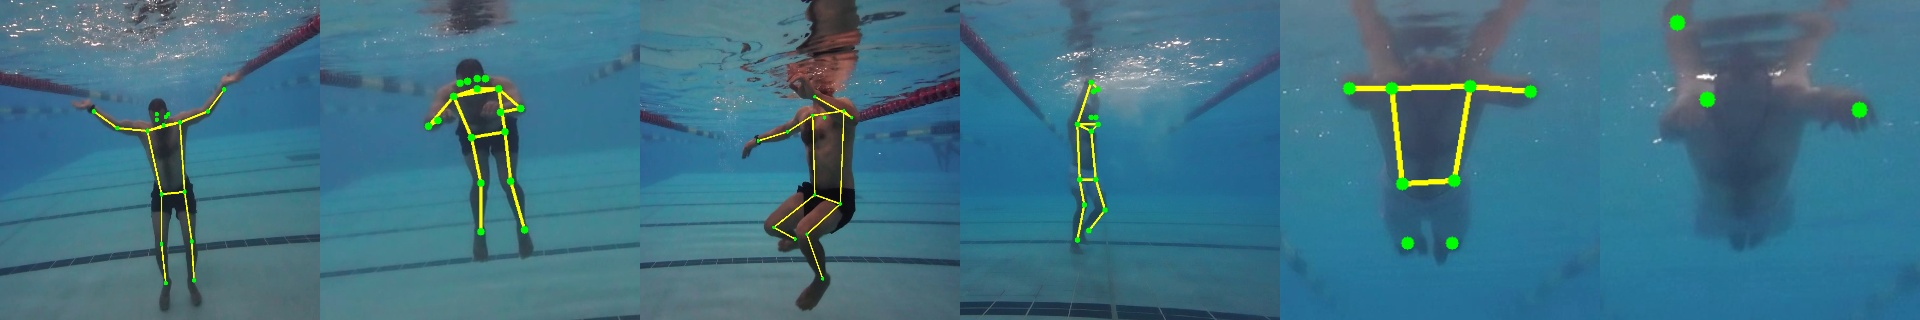

In [86]:
# 6. Look at 6 training labels drawn from the YOLO txt files (are the pseudo-labels plausible?)
import cv2, numpy as np, random
from IPython.display import Image, display
SK = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]
def draw_yolo(img_path, lbl_path):
    im = cv2.imread(str(img_path)); h, w = im.shape[:2]
    t = [float(v) for v in open(lbl_path).read().split()]
    cx, cy, bw, bh = t[1] * w, t[2] * h, t[3] * w, t[4] * h
    k = np.array(t[5:]).reshape(17, 3) * [w, h, 1]
    for a, b in SK:
        if k[a][2] > 0 and k[b][2] > 0:
            cv2.line(im, tuple(int(v) for v in k[a][:2]), tuple(int(v) for v in k[b][:2]), (0, 255, 255), 3)
    for x, y, v in k:
        if v > 0:
            cv2.circle(im, (int(x), int(y)), 6, (0, 255, 0), -1)
    r = int(max(bw, bh) * 0.8)
    crop = im[max(0, int(cy) - r):int(cy) + r, max(0, int(cx) - r):int(cx) + r]
    return cv2.resize(crop, (320, 320))
imgs = sorted((DS / 'images' / 'train').glob('*.jpg'))
pick = random.Random(0).sample(imgs, 6)
sheet = np.hstack([draw_yolo(p, DS / 'labels' / 'train' / (p.stem + '.txt')) for p in pick])
cv2.imwrite(str(REF_DIR / 'train_label_check.jpg'), sheet)
display(Image(str(REF_DIR / 'train_label_check.jpg')))


## 7. Baseline before training

In [87]:
# 7. Baseline: PRETRAINED YOLO11s-pose vs AI references on the 27 test frames (agreement with ViTPose)
!cd /content/pose_tools && python zero_shot_eval.py --gt "{REF_TEST}" --images "{SET}/images" --manifest "{SET}/manifest.csv" --split real_val --yolo-pose "{YOLO_PT}" --out "{REF_DIR}/eval_pretrained_test27.csv"


27 frames, split=real_val, group=all
{'model': 'yolo11s-pose', 'frames': 27, 'no_prediction': 5, 'frames_ge3_confident_upper': 0.815, 'latency_ms_median_per_person': 15.4, 'PCK@0.05_upper': 0.2, 'PCK@0.1_upper': 0.325, 'PCK@0.2_upper': 0.4, 'PCK@0.05_all': 0.173, 'PCK@0.1_all': 0.283, 'PCK@0.2_all': 0.376}
wrote /content/drive/MyDrive/pose_baseline/ai_reference/eval_pretrained_test27.csv


## 8. Training (A100: about 10-20 min, estimate)

In [88]:
# 8. Train (resumable). imgsz 960 because many swimmers are only ~80-200 px tall in 1920x1080 frames.
from ultralytics import YOLO
NAME = 'yolo11s_pose_distill_960'
last = RUNS / NAME / 'weights' / 'last.pt'
if last.is_file():
    print('resuming from', last)
    YOLO(str(last)).train(resume=True)
else:
    YOLO(str(YOLO_PT)).train(
        data=str(DS / 'data.yaml'), imgsz=960, epochs=100, patience=30, batch=16, workers=8,
        seed=42, deterministic=True, cos_lr=True, fliplr=0.5, flipud=0.0,
        project=str(RUNS), name=NAME, exist_ok=True, plots=True)
BEST = RUNS / NAME / 'weights' / 'best.pt'
print('best weights:', BEST, BEST.is_file())


Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/pose_yolo_ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/pose_baseline/models/yolo11s-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_p

## 9. Losses

 epoch  train/box_loss  train/pose_loss  train/kobj_loss  metrics/mAP50(P)  metrics/mAP50-95(P)  val/box_loss  val/pose_loss
     1         1.76406          5.92390          0.63993           0.01292              0.00129       1.14550        9.30438
    11         1.33512          4.62016          0.47419           0.01059              0.00284       1.65844        9.26481
    21         1.22604          4.31618          0.45807           0.03015              0.00612       1.33954        8.88320
    31         1.11824          3.71975          0.40987           0.04644              0.01342       1.01749        9.04282
    41         1.03708          3.53369          0.39489           0.03656              0.01527       0.94195        8.75607
    51         0.93767          3.06543          0.38071           0.15460              0.03695       0.96286        8.14152
    61         0.92393          2.75185          0.35370           0.11100              0.03487       0.88238        8.61000


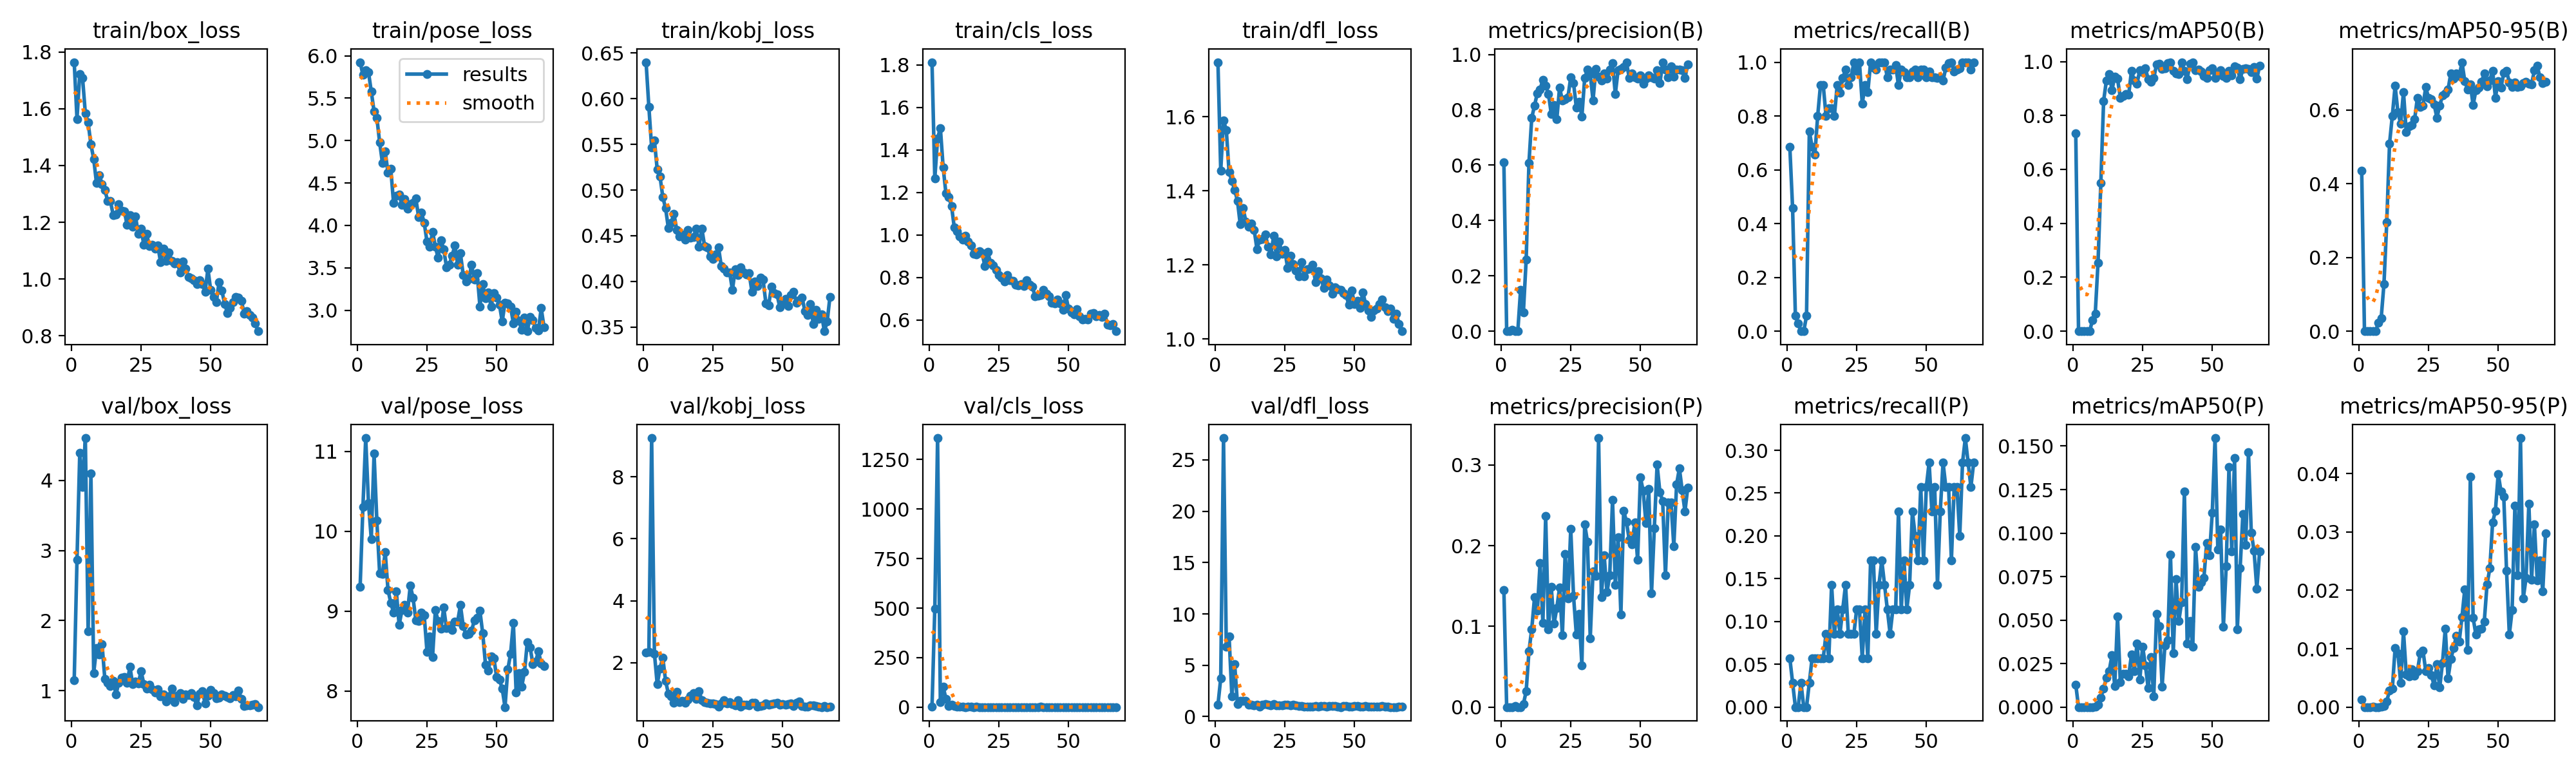

In [89]:
# 9. Losses and validation metrics per epoch (val = agreement with ViTPose on 35 frames)
import pandas as pd
res = pd.read_csv(RUNS / NAME / 'results.csv')
res.columns = [c.strip() for c in res.columns]
cols = [c for c in res.columns if c in ('epoch', 'train/box_loss', 'train/pose_loss', 'train/kobj_loss',
        'val/box_loss', 'val/pose_loss', 'metrics/mAP50(P)', 'metrics/mAP50-95(P)')]
print(res[cols].iloc[::10].to_string(index=False))
print('...last epoch:'); print(res[cols].tail(1).to_string(index=False))
display(Image(str(RUNS / NAME / 'results.png')))


## 10. Evaluation and comparison

In [90]:
# 10. FINE-TUNED YOLO11s-pose vs AI references on the 27 test frames, and comparison with the pretrained model
BEST = RUNS / NAME / 'weights' / 'best.pt'
!cd /content/pose_tools && python zero_shot_eval.py --gt "{REF_TEST}" --images "{SET}/images" --manifest "{SET}/manifest.csv" --split real_val --yolo-pose "{BEST}" --out "{REF_DIR}/eval_finetuned_test27.csv"
pre = pd.read_csv(REF_DIR / 'eval_pretrained_test27.csv'); pre['model'] = 'pretrained yolo11s-pose'
fin = pd.read_csv(REF_DIR / 'eval_finetuned_test27.csv'); fin['model'] = 'fine-tuned (distilled)'
cmp = pd.concat([pre, fin]).set_index('model').T
cmp.to_csv(REF_DIR / 'comparison_test27.csv')
print('AGREEMENT WITH ViTPose REFERENCES (ai_reference_unverified) - NOT ACCURACY')
print(cmp.to_string())


27 frames, split=real_val, group=all
{'model': 'best', 'frames': 27, 'no_prediction': 0, 'frames_ge3_confident_upper': 0.741, 'latency_ms_median_per_person': 18.3, 'PCK@0.05_upper': 0.225, 'PCK@0.1_upper': 0.417, 'PCK@0.2_upper': 0.617, 'PCK@0.05_all': 0.173, 'PCK@0.1_all': 0.321, 'PCK@0.2_all': 0.519}
wrote /content/drive/MyDrive/pose_baseline/ai_reference/eval_finetuned_test27.csv
AGREEMENT WITH ViTPose REFERENCES (ai_reference_unverified) - NOT ACCURACY
model                         pretrained yolo11s-pose  fine-tuned (distilled)
frames                                         27.000                  27.000
no_prediction                                   5.000                   0.000
frames_ge3_confident_upper                      0.815                   0.741
latency_ms_median_per_person                   15.400                  18.300
PCK@0.05_upper                                  0.200                   0.225
PCK@0.1_upper                                   0.325                  

## 11. Confidence statistics

In [91]:
# 11. Keypoint confidence on the 27 test frames: pretrained vs fine-tuned
import sys
sys.path.insert(0, '/content/pose_tools')
from pose_common import COCO17, iou
import json
ref = json.loads(REF_TEST.read_text())
boxes = {i['file_name']: None for i in ref['images']}
for a in ref['annotations']:
    x, y, w, h = a['bbox']
    boxes[next(i['file_name'] for i in ref['images'] if i['id'] == a['image_id'])] = (x, y, x + w, y + h)
def confs(weights):
    m = YOLO(str(weights)); out = []
    for n, box in boxes.items():
        r = m.predict(str(SET / 'images' / n), verbose=False)[0]
        if r.keypoints is None or len(r.boxes) == 0:
            out.append(np.zeros(17)); continue
        ious = [iou(tuple(b), box) for b in r.boxes.xyxy.cpu().numpy()]
        i = int(np.argmax(ious))
        out.append(r.keypoints.conf[i].cpu().numpy() if ious[i] >= 0.3 else np.zeros(17))
    return np.array(out)
cp, cf = confs(YOLO_PT), confs(BEST)
print(f'{"keypoint":16s} pretrained mean / >=0.5   fine-tuned mean / >=0.5')
for k, nme in enumerate(COCO17):
    print(f'{nme:16s} {cp[:, k].mean():.2f} / {(cp[:, k] >= 0.5).mean():.2f}            {cf[:, k].mean():.2f} / {(cf[:, k] >= 0.5).mean():.2f}')


keypoint         pretrained mean / >=0.5   fine-tuned mean / >=0.5
nose             0.34 / 0.33            0.32 / 0.33
left_eye         0.25 / 0.22            0.52 / 0.48
right_eye        0.23 / 0.22            0.53 / 0.56
left_ear         0.38 / 0.41            0.25 / 0.15
right_ear        0.32 / 0.19            0.30 / 0.26
left_shoulder    0.78 / 0.81            0.72 / 0.70
right_shoulder   0.75 / 0.78            0.73 / 0.74
left_elbow       0.72 / 0.81            0.61 / 0.67
right_elbow      0.71 / 0.78            0.66 / 0.70
left_wrist       0.67 / 0.74            0.55 / 0.52
right_wrist      0.66 / 0.78            0.59 / 0.59
left_hip         0.78 / 0.78            0.45 / 0.41
right_hip        0.78 / 0.81            0.47 / 0.44
left_knee        0.73 / 0.78            0.45 / 0.44
right_knee       0.73 / 0.78            0.45 / 0.48
left_ankle       0.63 / 0.74            0.45 / 0.44
right_ankle      0.62 / 0.74            0.46 / 0.44


## 12. Visual samples

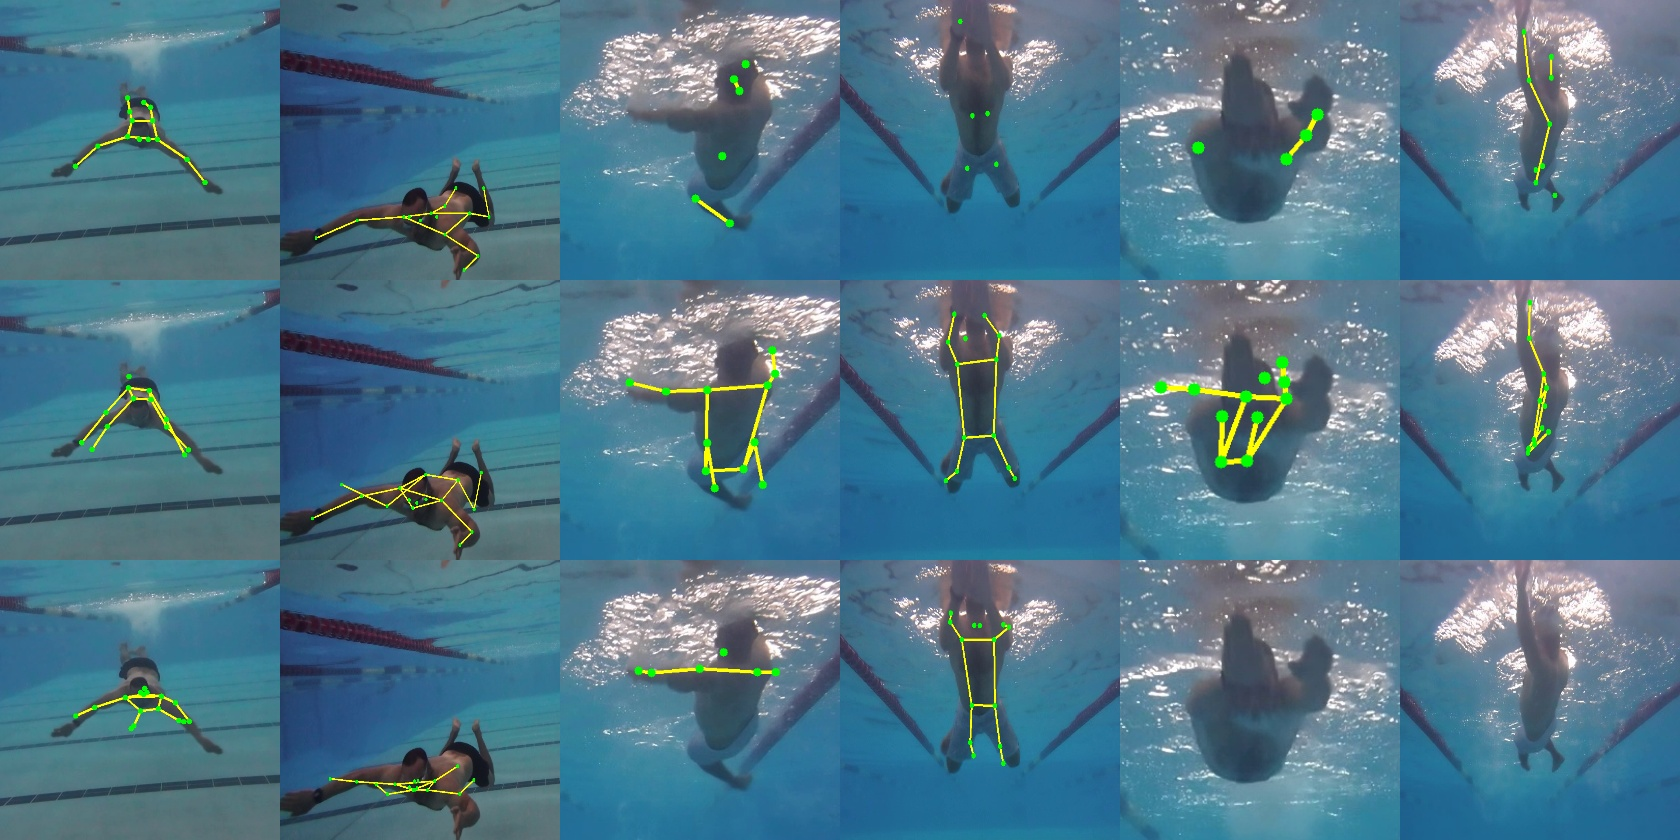

In [92]:
# 12. Visual samples on test frames: row 1 AI reference (ViTPose), row 2 pretrained YOLO, row 3 fine-tuned YOLO
def draw_kp(img, k, box, thr=0.5):
    im = img.copy()
    if k is not None:
        for a, b in SK:
            if k[a][2] >= thr and k[b][2] >= thr:
                cv2.line(im, tuple(int(v) for v in k[a][:2]), tuple(int(v) for v in k[b][:2]), (0, 255, 255), 3)
        for x, y, c in k:
            if c >= thr:
                cv2.circle(im, (int(x), int(y)), 6, (0, 255, 0), -1)
    x1, y1, x2, y2 = (int(v) for v in box)
    cx, cy, r = (x1 + x2) // 2, (y1 + y2) // 2, int(max(x2 - x1, y2 - y1) * 0.8)
    return cv2.resize(im[max(0, cy - r):cy + r, max(0, cx - r):cx + r], (280, 280))
def yolo_kp(m, img, box):
    r = m.predict(img, verbose=False)[0]
    if r.keypoints is None or len(r.boxes) == 0:
        return None
    ious = [iou(tuple(b), box) for b in r.boxes.xyxy.cpu().numpy()]
    i = int(np.argmax(ious))
    if ious[i] < 0.3:
        return None
    return np.concatenate([r.keypoints.xy[i].cpu().numpy(), r.keypoints.conf[i].cpu().numpy()[:, None]], 1)
mp, mf = YOLO(str(YOLO_PT)), YOLO(str(BEST))
refk = {next(i['file_name'] for i in ref['images'] if i['id'] == a['image_id']):
        np.array(a['keypoints']).reshape(17, 3) for a in ref['annotations']}
show = ['frame_08141.jpg', 'frame_08281.jpg', 'frame_40752.jpg', 'frame_47225.jpg', 'frame_48666.jpg', 'frame_50284.jpg']
rows = [[], [], []]
for n in show:
    img = cv2.imread(str(SET / 'images' / n)); b = boxes[n]
    rk = refk[n].copy(); rk[:, 2] = (rk[:, 2] > 0).astype(float)
    rows[0].append(draw_kp(img, rk, b)); rows[1].append(draw_kp(img, yolo_kp(mp, img, b), b)); rows[2].append(draw_kp(img, yolo_kp(mf, img, b), b))
sheet = np.vstack([np.hstack(r) for r in rows])
cv2.imwrite(str(REF_DIR / 'samples_ref_pretrained_finetuned.jpg'), sheet)
display(Image(str(REF_DIR / 'samples_ref_pretrained_finetuned.jpg')))


All metrics above are agreement with ViTPose pseudo-labels on frames from the same footage. They show whether the student learned the teacher, not whether either model is correct. Trusted accuracy needs human-annotated frames.